# FSE570 Capstone Project: Arizona Water Conservation Platform
**Team Adventurer:** Afshiya Roohi Shaik (`ashaik89@asu.edu`), Paul Lonsdorf (`tlonsdor@asu.edu`), Harshith Dharbi (`hdharbi@asu.edu`), Sneha Sai Kummara (`skummar3@asu.edu`)

## Phase 1: Data Collection, Cleaning, and Spatial Integration
This notebook executes Phase 1 of our methodology using the **ASU Arizona Water Observatory (AWO) OGC API**:
1. **Collect & Inspect Datasets:** Obtain the ADWR Well Registry/Depth-to-Water measurements (**Dataset 1**) and ASU Groundwater Basin & AMA boundaries (**Dataset 2**).
2. **Clean & Preprocess Data:** Standardize column schemas, remove duplicates, validate Arizona coordinates, and assess depth-to-water measurements.
3. **Spatial Integration:** Match well point coordinates into groundwater basin and AMA polygons using `geopandas.sjoin()`, and isolate unmatched wells for investigation.

In [31]:

!pip install pandas geopandas shapely pyproj requests matplotlib openpyxl

import os
import requests
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

# Configure display settings for cleaner DataFrame output in Jupyter
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 1000)

# Create output folders
RAW_DIR = "../data/raw"
PROCESSED_DIR = "../data/processed"
os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(PROCESSED_DIR, exist_ok=True)

# Define Target CRS: NAD83 / UTM Zone 12N (Standard for Arizona GIS)
TARGET_CRS = "EPSG:26912"

# Arizona Geographic Bounding Box (Decimal Degrees)
AZ_LAT_MIN, AZ_LAT_MAX = 31.30, 37.05
AZ_LON_MIN, AZ_LON_MAX = -114.85, -109.00

print("Environment and directories initialized successfully!")

Defaulting to user installation because normal site-packages is not writeable
Environment and directories initialized successfully!



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\plons\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
AWO_BASE_URL = "https://arizonawaterobservatory-api.rtd.asu.edu/collections"

# DATASET 1: ADWR Well Registry & Depth-to-Water Measurements
WELLS_COLLECTION = "ArizonaWaterWells"

# DATASET 2: ASU Geospatial Boundaries (Groundwater Basins & Active Management Areas)
BASINS_COLLECTION = "ASU_Groundwater_Basins_Aggregated_Grace"
AMA_COLLECTION = "Active_Management_Areas_2025"

# 1. Download Dataset 2 (Groundwater Basin & AMA Polygons)
print("1. Downloading ASU Groundwater Basin & AMA Polygons...")
basins_url = f"{AWO_BASE_URL}/{BASINS_COLLECTION}/items?f=json&limit=500"
ama_url = f"{AWO_BASE_URL}/{AMA_COLLECTION}/items?f=json&limit=100"

gdf_basins = gpd.read_file(basins_url)
gdf_ama = gpd.read_file(ama_url)

gdf_basins.to_file(f"{RAW_DIR}/awo_groundwater_basins.geojson", driver="GeoJSON")
gdf_ama.to_file(f"{RAW_DIR}/awo_ama_boundaries.geojson", driver="GeoJSON")

# 2. Download Dataset 1 (ADWR Well Registry & Water Levels) using gpd.read_file per batch
print("2. Downloading ADWR Well Registry & Depth-to-Water Records...")
well_limit = 5000
batch_size = 1000
gdf_batches = []

for offset in range(0, well_limit, batch_size):
    wells_url = f"{AWO_BASE_URL}/{WELLS_COLLECTION}/items?f=json&limit={batch_size}&offset={offset}"
    batch_gdf = gpd.read_file(wells_url)
    if batch_gdf.empty:
        break
    gdf_batches.append(batch_gdf)
    print(f"   Fetched {sum(len(b) for b in gdf_batches)} well records...")

gdf_wells = pd.concat(gdf_batches, ignore_index=True)
gdf_wells = gpd.GeoDataFrame(gdf_wells, geometry="geometry", crs="EPSG:4326")
gdf_wells.to_file(f"{RAW_DIR}/awo_adwr_wells_raw.geojson", driver="GeoJSON")

print("\n=== STEP 1: DATASET INSPECTION SUMMARY ===")
print(f"Dataset 1 (ADWR Wells)          -> Shape: {gdf_wells.shape} | CRS: {gdf_wells.crs}")
print(f"Dataset 1 Columns               -> {list(gdf_wells.columns)}")
print(f"Dataset 2A (Groundwater Basins) -> Shape: {gdf_basins.shape} | CRS: {gdf_basins.crs}")
print(f"Dataset 2A Columns              -> {list(gdf_basins.columns)}")
print(f"Dataset 2B (AMA Boundaries)     -> Shape: {gdf_ama.shape} | CRS: {gdf_ama.crs}")

gdf_wells.head(3)

1. Downloading ASU Groundwater Basin & AMA Polygons...
2. Downloading ADWR Well Registry & Depth-to-Water Records...
   Fetched 1000 well records...
   Fetched 2000 well records...
   Fetched 3000 well records...
   Fetched 4000 well records...
   Fetched 5000 well records...

=== STEP 1: DATASET INSPECTION SUMMARY ===
Dataset 1 (ADWR Wells)          -> Shape: (5000, 4) | CRS: EPSG:4326
Dataset 1 Columns               -> ['id', 'location_id', 'properties', 'geometry']
Dataset 2A (Groundwater Basins) -> Shape: (53, 9) | CRS: EPSG:4326
Dataset 2A Columns              -> ['ogc_fid', 'objectid', 'basin_name', 'name_abbr', 'basin_na_1', 'shape__are', 'shape__len', 'gws', 'geometry']
Dataset 2B (AMA Boundaries)     -> Shape: (7, 10) | CRS: EPSG:4326


,id,location_id,properties,geometry
0,060000,060000,"{'WELLS_55_AMA': 'PINAL AMA', 'WELLS_55_ZIP': ...",POINT (-111.81405 32.95186)
1,082721,082721,"{'WELLS_55_AMA': 'HARQUAHALA INA', 'WELLS_55_Z...",POINT (-113.1706 33.50089)
2,083226,083226,"{'WELLS_55_AMA': 'WILLCOX AMA', 'WELLS_55_ZIP'...",POINT (-109.80551 32.29512)


In [4]:
import json

df = gdf_wells.copy()

# 1. Unpack the nested 'properties' dictionary into flat DataFrame columns
if "properties" in df.columns:
    props_series = df["properties"].apply(
        lambda x: json.loads(x) if isinstance(x, str) else (x if isinstance(x, dict) else {})
    )
    props_df = pd.json_normalize(props_series)
    # If there was a double-nested 'properties.properties' prefix, strip it cleanly
    props_df.columns = [c.replace("properties.", "") for c in props_df.columns]
    df = gpd.GeoDataFrame(
        pd.concat([df.drop(columns=["properties"]).reset_index(drop=True), props_df.reset_index(drop=True)], axis=1),
        geometry="geometry",
        crs=gdf_wells.crs
    )

# Standardize column names to uppercase and remove duplicate column names if any
df.columns = [col.upper() if col != "geometry" else "geometry" for col in df.columns]
df = df.loc[:, ~df.columns.duplicated()]

non_geom_cols = [c for c in df.columns if c != "geometry"]
print(f"Total Unpacked Attribute Columns ({len(non_geom_cols)}): {non_geom_cols[:10]} ...")

# 2. Identify Primary ID, Depth-to-Water, and Date columns from the unpacked ADWR schema
id_col = next((c for c in ["ID", "LOCATION_ID", "WELLS_55_REGISTRY_I"] if c in df.columns), non_geom_cols[0])
dtw_cols_present = [
    c for c in non_geom_cols
    if any(k in c for k in ["WATER_LEVE", "WELL_DEPTH", "CASING_DEP", "DRAW_DOWN", "DTW", "STATIC"])
]
date_candidates = [
    c for c in non_geom_cols
    if any(k in c for k in ["APPLICATIO", "INSTALLED", "COMPLETION", "APPROVED", "DATE"])
]

print(f"Primary ID Column Selected : {id_col}")
print(f"Water/Depth Columns Found  : {dtw_cols_present}")
print(f"Date/Time Columns Found    : {date_candidates}")

# 3. Remove duplicate well records
initial_count = len(df)
df = df.drop_duplicates(subset=[id_col], keep="first").copy()
print(f"\nRemoved {initial_count - len(df)} duplicate well records.")

# 4. Validate geographic coordinates within Arizona bounding box
df["LON_DD"] = df.geometry.x
df["LAT_DD"] = df.geometry.y

valid_coord_mask = (
    df.geometry.notna()
    & (~df.geometry.is_empty)
    & df["LAT_DD"].between(AZ_LAT_MIN, AZ_LAT_MAX)
    & df["LON_DD"].between(AZ_LON_MIN, AZ_LON_MAX)
)

gdf_invalid_coords = df[~valid_coord_mask].copy()
gdf_valid_wells = df[valid_coord_mask].copy()
print(f"Valid Arizona coordinates: {len(gdf_valid_wells)} | Invalid/Out-of-bounds coordinates: {len(gdf_invalid_coords)}")

# 5. Assess missing depth-to-water measurements and standardize numeric types
print("\nMissing Value Assessment (Water Level & Depth Columns):")
for col in dtw_cols_present:
    gdf_valid_wells[col] = pd.to_numeric(gdf_valid_wells[col], errors="coerce")
    # Treat 0 as missing if recorded as placeholder 0 in water level / depth
    missing_pct = (gdf_valid_wells[col].isna() | (gdf_valid_wells[col] <= 0)).mean() * 100
    print(f" - {col}: {missing_pct:.2f}% missing or zero")

# Set USABLE_DTW_FT to WELLS_55_WATER_LEVE (Depth to Water in feet)
if "WELLS_55_WATER_LEVE" in gdf_valid_wells.columns:
    gdf_valid_wells["USABLE_DTW_FT"] = gdf_valid_wells["WELLS_55_WATER_LEVE"].replace(0, float("nan"))
elif dtw_cols_present:
    gdf_valid_wells["USABLE_DTW_FT"] = gdf_valid_wells[dtw_cols_present[0]].replace(0, float("nan"))

# 6. Standardize Date Formats (e.g. WELLS_55_APPLICATIO = '1984/06/29')
for dcol in date_candidates:
    gdf_valid_wells[f"{dcol}_CLEAN"] = pd.to_datetime(gdf_valid_wells[dcol], errors="coerce")

# Display cleaned preview table
preview_cols = [
    c for c in [id_col, "LAT_DD", "LON_DD", "USABLE_DTW_FT", "WELLS_55_WELL_DEPTH", "WELLS_55_APPLICATIO_CLEAN"]
    if c in gdf_valid_wells.columns
]
gdf_valid_wells[preview_cols].head()

Total Unpacked Attribute Columns (54): ['ID', 'LOCATION_ID', 'WELLS_55_AMA', 'WELLS_55_ZIP', 'WELLS_55_CITY', 'WELLS_55_ZIP4', 'WELLS_55_STATE', 'WELLS_55_COUNTY', 'WELLS_55_PROGRAM', 'WELLS_55_SECTION'] ...
Primary ID Column Selected : ID
Water/Depth Columns Found  : ['WELLS_55_DRAW_DOWN', 'WELLS_55_CASING_DEP', 'WELLS_55_WATER_LEVE', 'WELLS_55_WELL_DEPTH']
Date/Time Columns Found    : ['WELLS_55_APPROVED', 'WELLS_55_INSTALLED', 'WELLS_55_APPLICATIO', 'WELLS_55_COMPLETION']

Removed 0 duplicate well records.
Valid Arizona coordinates: 5000 | Invalid/Out-of-bounds coordinates: 0

Missing Value Assessment (Water Level & Depth Columns):
 - WELLS_55_DRAW_DOWN: 82.98% missing or zero
 - WELLS_55_CASING_DEP: 29.44% missing or zero
 - WELLS_55_WATER_LEVE: 33.54% missing or zero
 - WELLS_55_WELL_DEPTH: 25.16% missing or zero


C:\Users\plons\AppData\Local\Temp\ipykernel_492\1962810512.py:77: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  gdf_valid_wells[f"{dcol}_CLEAN"] = pd.to_datetime(gdf_valid_wells[dcol], errors="coerce")


,ID,LAT_DD,LON_DD,USABLE_DTW_FT,WELLS_55_WELL_DEPTH,WELLS_55_APPLICATIO_CLEAN
0,060000,32.951858,-111.814054,257.0,1790,1984-06-29
1,082721,33.500894,-113.170597,NaN,0,1979-10-15
2,083226,32.295123,-109.805511,162.0,162,1980-01-07
3,083578,31.595636,-111.036613,12.0,101,1980-02-15
4,083716,31.422762,-110.252043,NaN,0,1980-03-20


In [5]:
# 1. Reproject all layers to NAD83 / UTM Zone 12N (EPSG:26912) for accurate spatial join
gdf_wells_utm = gdf_valid_wells.to_crs(TARGET_CRS)
gdf_basins_utm = gdf_basins.to_crs(TARGET_CRS)
gdf_ama_utm = gdf_ama.to_crs(TARGET_CRS)

# Fix any topological self-intersections in polygon boundaries
gdf_basins_utm["geometry"] = gdf_basins_utm.geometry.buffer(0)
gdf_ama_utm["geometry"] = gdf_ama_utm.geometry.buffer(0)

# Automatically identify the Basin Name and AMA Name columns
basin_name_col = next(
    (c for c in gdf_basins_utm.columns if "basin" in c.lower() or "name" in c.lower()),
    [c for c in gdf_basins_utm.columns if c != "geometry"][0]
)
ama_name_col = next(
    (c for c in gdf_ama_utm.columns if "name" in c.lower() or "basin" in c.lower() or "ama" in c.lower()),
    [c for c in gdf_ama_utm.columns if c != "geometry"][0]
)

gdf_basins_sub = gdf_basins_utm[[basin_name_col, "geometry"]].rename(columns={basin_name_col: "ASSIGNED_BASIN_NAME"})
gdf_ama_sub = gdf_ama_utm[[ama_name_col, "geometry"]].rename(columns={ama_name_col: "ASSIGNED_AMA_NAME"})

# 2. Spatial Join: Match Wells (Dataset 1) to Groundwater Basins & AMAs (Dataset 2)
gdf_joined = gpd.sjoin(gdf_wells_utm, gdf_basins_sub, how="left", predicate="within").drop(columns=["index_right"], errors="ignore")
gdf_joined = gpd.sjoin(gdf_joined, gdf_ama_sub, how="left", predicate="within").drop(columns=["index_right"], errors="ignore")
gdf_joined["ASSIGNED_AMA_NAME"] = gdf_joined["ASSIGNED_AMA_NAME"].fillna("NON-AMA")

# 3. Separate Matched vs. Unmatched Wells
unmatched_mask = gdf_joined["ASSIGNED_BASIN_NAME"].isna()
gdf_matched = gdf_joined[~unmatched_mask].copy()
gdf_unmatched = gdf_joined[unmatched_mask].copy()

print("=== STEP 3: SPATIAL MERGE RESULTS ===")
print(f"Wells Matched to a Groundwater Basin : {len(gdf_matched)}")
print(f"Wells Outside Basin Polygons         : {len(gdf_unmatched)}")

# 4. Export Cleaned & Merged Data + Unmatched Investigation Report
pd.DataFrame(gdf_matched.drop(columns="geometry")).to_csv(f"{PROCESSED_DIR}/phase1_merged_wells_basins.csv", index=False)

df_investigation = pd.concat([
    pd.DataFrame(gdf_invalid_coords.drop(columns="geometry", errors="ignore")).assign(INVESTIGATION_FLAG="Invalid_Coordinates"),
    pd.DataFrame(gdf_unmatched.drop(columns="geometry", errors="ignore")).assign(INVESTIGATION_FLAG="Outside_Basin_Polygons")
], ignore_index=True)
df_investigation.to_csv(f"{PROCESSED_DIR}/phase1_unmatched_or_invalid_wells.csv", index=False)

print(f"\nSaved merged dataset to: {PROCESSED_DIR}/phase1_merged_wells_basins.csv")
print(f"Saved investigation report to: {PROCESSED_DIR}/phase1_unmatched_or_invalid_wells.csv")

print("\nTop 10 Groundwater Basins by Matched Well Count:")
display(gdf_matched["ASSIGNED_BASIN_NAME"].value_counts().head(10).to_frame(name="Well_Count"))

=== STEP 3: SPATIAL MERGE RESULTS ===
Wells Matched to a Groundwater Basin : 5000
Wells Outside Basin Polygons         : 0

Saved merged dataset to: ../data/processed/phase1_merged_wells_basins.csv
Saved investigation report to: ../data/processed/phase1_unmatched_or_invalid_wells.csv

Top 10 Groundwater Basins by Matched Well Count:


,Well_Count
ASSIGNED_BASIN_NAME,
PHOENIX AMA,968
PRESCOTT AMA,552
VERDE RIVER,491
LITTLE COLORADO RIVER PLATEAU,429
TUCSON AMA,419
UPPER SAN PEDRO,297
WILLCOX,150
YUMA,150
PINAL AMA,149


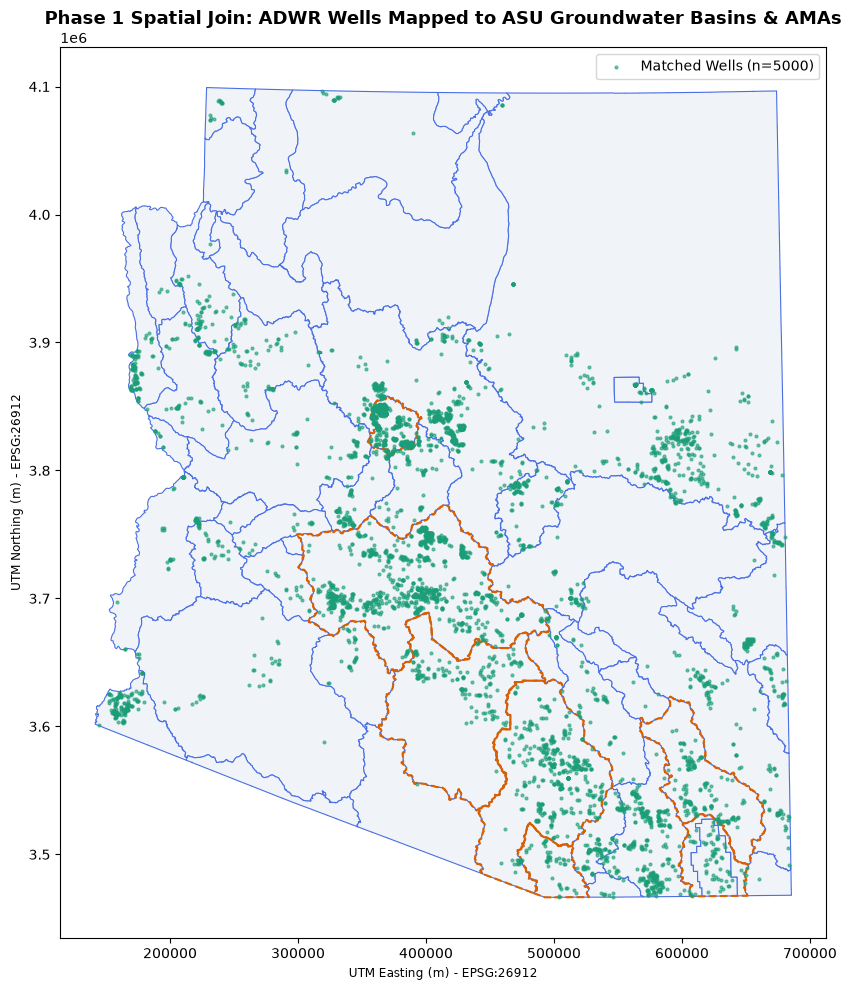

In [6]:
fig, ax = plt.subplots(figsize=(10, 10))

# Plot Groundwater Basin polygons
gdf_basins_utm.plot(ax=ax, color="#f0f4f8", edgecolor="#4a6fe3", linewidth=0.8)

# Plot Active Management Areas (AMAs) in a dashed orange outline
gdf_ama_utm.plot(ax=ax, facecolor="none", edgecolor="#d95f02", linewidth=1.5, linestyle="--")

# Plot Matched vs. Unmatched Wells
gdf_matched.plot(ax=ax, color="#1b9e77", markersize=4, alpha=0.6, label=f"Matched Wells (n={len(gdf_matched)})")
if len(gdf_unmatched) > 0:
    gdf_unmatched.plot(ax=ax, color="#e7298a", markersize=20, marker="x", label=f"Unmatched Wells (n={len(gdf_unmatched)})")

ax.set_title("Phase 1 Spatial Join: ADWR Wells Mapped to ASU Groundwater Basins & AMAs", fontsize=13, fontweight="bold")
ax.set_xlabel("UTM Easting (m) - EPSG:26912")
ax.set_ylabel("UTM Northing (m) - EPSG:26912")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(f"{PROCESSED_DIR}/phase1_spatial_join_map.png", dpi=300)
plt.show()

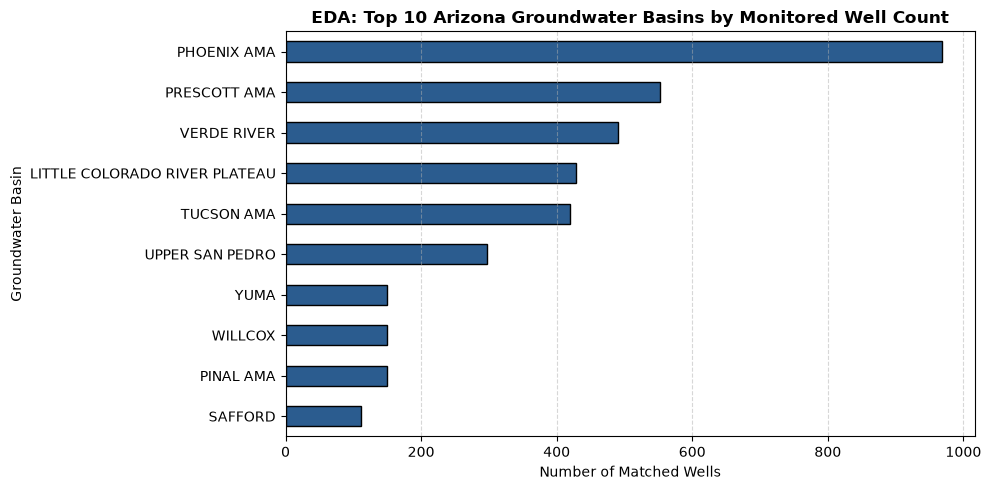


Summary of Depth-to-Water (ft) Across Top 10 Basins:


,Well_Count,Mean_DTW_ft,Median_DTW_ft,Max_DTW_ft
ASSIGNED_BASIN_NAME,,,,
PHOENIX AMA,670,205.77,143.0,2168.0
PRESCOTT AMA,401,174.56,150.0,608.0
VERDE RIVER,342,140.42,89.5,975.0
LITTLE COLORADO RIVER PLATEAU,301,232.04,208.0,890.0
TUCSON AMA,244,248.04,200.0,940.0
UPPER SAN PEDRO,163,179.02,137.0,785.0
YUMA,112,60.12,62.5,851.0
WILLCOX,101,192.32,175.0,540.0
PINAL AMA,90,336.32,328.5,750.0


In [7]:
fig, ax = plt.subplots(figsize=(10, 5))

top_basins = gdf_matched["ASSIGNED_BASIN_NAME"].value_counts().head(10).sort_values(ascending=True)
top_basins.plot(kind="barh", color="#2b5c8f", edgecolor="black", ax=ax)

ax.set_title("EDA: Top 10 Arizona Groundwater Basins by Monitored Well Count", fontsize=12, fontweight="bold")
ax.set_xlabel("Number of Matched Wells")
ax.set_ylabel("Groundwater Basin")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(f"{PROCESSED_DIR}/phase1_eda_top_basins.png", dpi=300)
plt.show()

# Summary statistics table by Basin
if gdf_matched["USABLE_DTW_FT"].notna().any():
    print("\nSummary of Depth-to-Water (ft) Across Top 10 Basins:")
    basin_summary = (
        gdf_matched.groupby("ASSIGNED_BASIN_NAME")["USABLE_DTW_FT"]
        .agg(Well_Count="count", Mean_DTW_ft="mean", Median_DTW_ft="median", Max_DTW_ft="max")
        .sort_values(by="Well_Count", ascending=False)
        .head(10)
    )
    display(basin_summary.round(2))

## Phase 2: Historical Trend Analysis & Predictive Modeling
This notebook continues our methodology into Phase 2 using the **ADWR Groundwater Site Inventory (GWSI)** historical measurement records:
1. **Load & Integrate Historical Measurements:** Merge GWSI site metadata (`GWSI_SITES`) with decades of depth-to-water readings (`GWSI_WW_LEVELS`).
2. **Standardize & Explore:** Clean date and numeric fields, assign each monitoring site to a groundwater basin, and visualize long-term depth-to-water trends.
3. **Feature Engineering:** Aggregate readings to basin-year panels and construct lagged/rolling depth-to-water features plus the next-year prediction target.
4. **Train Random Forest Model:** Split the panel chronologically and fit a Random Forest regression pipeline to predict next-year basin-level depth-to-water.
5. **Evaluate Model:** Compare Random Forest performance (MAE/RMSE) against a persistence baseline.

### Load & Integrate Historical Measurements

In [8]:
sites = pd.read_csv(
    "../data/raw/GWSI_SITES.csv",
    dtype=str
)

levels = pd.read_csv(
    "../data/raw/GWSI_WW_LEVELS.csv",
    dtype=str
)

# Standardize column names
sites.columns = sites.columns.str.upper().str.strip()
levels.columns = levels.columns.str.upper().str.strip()

print("Sites:", sites.shape)
print("Water-level observations:", levels.shape)

display(levels.head())

Sites: (46860, 48)
Water-level observations: (308610, 8)


,WLWA_SITE_WELL_SITE_ID,WLWA_ID,WLWA_MEASUREMENT_DATE,WLWA_DEPTH_TO_WATER,WLWA_WATER_LEVEL_ELEVATION,WLWA_SOURCE_CODE,WLWA_METHOD_CODE,WLWA_REMARK_CODE
0,312119110351701,255578,4/6/1955,0.51,4649.49,U,S,S
1,312119110351701,255579,4/28/1955,0.42,4649.58,U,S,NaN
2,312119110351701,255580,5/25/1955,0.61,4649.39,U,S,NaN
3,312119110351701,255581,6/28/1955,0.74,4649.26,U,S,S
4,312119110351701,255582,7/18/1955,0.68,4649.32,U,S,NaN


In [9]:
# Join historical measurements to site records
measurements = levels.merge(
    sites,
    left_on="WLWA_SITE_WELL_SITE_ID",
    right_on="SITE_WELL_SITE_ID",
    how="left",
    validate="many_to_one",
    indicator=True
)

print(measurements["_merge"].value_counts())

_merge
both          308610
left_only          0
right_only         0
Name: count, dtype: int64


#### Standardize Observation Fields

In [10]:
measurements["MEASUREMENT_DATE"] = pd.to_datetime(
    measurements["WLWA_MEASUREMENT_DATE"],
    errors="coerce"
)

measurements["DTW_FT"] = pd.to_numeric(
    measurements["WLWA_DEPTH_TO_WATER"],
    errors="coerce"
)

measurements["SITE_ID"] = measurements[
    "WLWA_SITE_WELL_SITE_ID"
]

# Preserve negative values and zero values.
# Keep source, method, and remark information for quality checks.

print(measurements[
    ["SITE_ID", "MEASUREMENT_DATE", "DTW_FT"]
].describe(include="all"))

                SITE_ID               MEASUREMENT_DATE         DTW_FT
count            308610                         308282  290296.000000
unique            37584                            NaN            NaN
top     395909110530701                            NaN            NaN
freq               4878                            NaN            NaN
mean                NaN  1991-05-17 19:14:34.256687104     188.780573
min                 NaN            1901-03-14 00:00:00     -97.900000
25%                 NaN            1974-03-15 00:00:00      55.300000
50%                 NaN            1993-11-16 00:00:00     144.495000
75%                 NaN            2011-03-02 00:00:00     282.000000
max                 NaN            2026-07-08 00:00:00    2875.000000
std                 NaN                            NaN     173.640462


### Exploratory Data Analysis

In [ ]:
# visualize historical groundwater measurements for the top 5 most-measured sites
site_counts = measurements.groupby("SITE_ID").size().sort_values(ascending=False)
sample_sites = site_counts.head(5).index

fig, ax = plt.subplots(figsize=(12, 6))
for site in sample_sites:
    temp = measurements[
        measurements["SITE_ID"] == site
    ].dropna(subset=["DTW_FT", "MEASUREMENT_DATE"])

    temp = temp.sort_values("MEASUREMENT_DATE")

    ax.plot(
        temp["MEASUREMENT_DATE"],
        temp["DTW_FT"],
        linewidth=1.2,
        alpha=0.85,
        label=f"Site {site} (n={site_counts[site]:,})"
    )

# Depth-to-water is "lower is better" (shallower = healthier aquifer), so invert
# the y-axis: a declining water table then reads as a falling line, matching
# how hydrologists read these records.
ax.invert_yaxis()

ax.set_xlabel("Measurement Date")
ax.set_ylabel("Depth to Water (ft, inverted)")
ax.set_title("Historical Groundwater Measurements: 5 Most-Measured Sites", fontsize=13, fontweight="bold")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# visualize the number of groundwater measurements by year
measurements["YEAR"] = (
    measurements["MEASUREMENT_DATE"].dt.year
)

year_counts = measurements.groupby("YEAR").size().astype(int)

# A continuous ~125-year time series reads as a line/area chart, not a
# categorical bar chart (125 bars made the year axis unreadable).
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(year_counts.index, year_counts.values, color="#2b5c8f", linewidth=1.5)
ax.fill_between(year_counts.index, year_counts.values, color="#2b5c8f", alpha=0.15)

ax.set_title("Groundwater Measurements by Year (Monitoring Effort Over Time)", fontsize=13, fontweight="bold")
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Number of Measurements", fontsize=12)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# groundwater trends by basin
# Assign each historical measurement site to a groundwater basin.
site_locations = measurements[
    ["SITE_ID", "SITE_LATITUDE_DECIMAL", "SITE_LONGIT_DECIMAL"]
].drop_duplicates("SITE_ID").copy()

site_locations["SITE_LATITUDE_DECIMAL"] = pd.to_numeric(
    site_locations["SITE_LATITUDE_DECIMAL"], errors="coerce"
)
site_locations["SITE_LONGIT_DECIMAL"] = pd.to_numeric(
    site_locations["SITE_LONGIT_DECIMAL"], errors="coerce"
)
site_locations = site_locations.dropna(
    subset=["SITE_LATITUDE_DECIMAL", "SITE_LONGIT_DECIMAL"]
)

gdf_sites = gpd.GeoDataFrame(
    site_locations,
    geometry=gpd.points_from_xy(
        site_locations["SITE_LONGIT_DECIMAL"],
        site_locations["SITE_LATITUDE_DECIMAL"],
    ),
    crs="EPSG:4326",
).to_crs(TARGET_CRS)

basin_lookup = gpd.sjoin(
    gdf_sites,
    gdf_basins_sub[["ASSIGNED_BASIN_NAME", "geometry"]],
    how="left",
    predicate="within",
)[["SITE_ID", "ASSIGNED_BASIN_NAME"]].drop_duplicates("SITE_ID")

measurements = measurements.drop(
    columns=["ASSIGNED_BASIN_NAME"], errors="ignore"
).merge(basin_lookup, on="SITE_ID", how="left")

# With 53 basins, overlaying one raw line per basin produces an unreadable,
# heavily overplotted chart (colors repeat past ~10 series, legend is 53
# entries long). Aggregate to a basin-year mean and render as a heatmap
# instead, which scales cleanly to many categories without a legend.
basin_year_mean = (
    measurements.dropna(subset=["ASSIGNED_BASIN_NAME", "DTW_FT", "YEAR"])
    .groupby(["ASSIGNED_BASIN_NAME", "YEAR"])["DTW_FT"]
    .mean()
    .reset_index(name="MEAN_DTW_FT")
)

# Order basins by how much data they have (most-monitored basins at the top)
basin_order = (
    basin_year_mean.groupby("ASSIGNED_BASIN_NAME")["MEAN_DTW_FT"]
    .count()
    .sort_values(ascending=False)
    .index
)

heatmap_data = basin_year_mean.pivot(
    index="ASSIGNED_BASIN_NAME", columns="YEAR", values="MEAN_DTW_FT"
).reindex(basin_order)

fig, ax = plt.subplots(figsize=(16, 12))
masked = np.ma.masked_invalid(heatmap_data.values)
cmap = plt.get_cmap("YlOrRd").copy()
cmap.set_bad(color="#e8e8e8")  # gray = no data that year

mesh = ax.pcolormesh(masked, cmap=cmap, shading="flat")

ax.set_yticks(np.arange(len(heatmap_data.index)) + 0.5)
ax.set_yticklabels(heatmap_data.index, fontsize=7)

# Thin year labels to every 10th year so the x-axis stays legible
year_cols = heatmap_data.columns.to_list()
tick_idx = [i for i, y in enumerate(year_cols) if y % 10 == 0]
ax.set_xticks([i + 0.5 for i in tick_idx])
ax.set_xticklabels([year_cols[i] for i in tick_idx], rotation=45, ha="right")

ax.set_xlabel("Year")
ax.set_ylabel("Groundwater Basin")
ax.set_title("Groundwater Trends by Basin: Mean Depth-to-Water (ft)", fontsize=13, fontweight="bold")

cbar = fig.colorbar(mesh, ax=ax, pad=0.01)
cbar.set_label("Mean Depth to Water (ft) -- darker = deeper / more stressed")

plt.tight_layout()
plt.savefig(f"{PROCESSED_DIR}/phase2_basin_depth_heatmap.png", dpi=200)
plt.show()


### Feature Engineering

In [24]:
valid = measurements.dropna(
    subset=[
        "SITE_ID",
        "MEASUREMENT_DATE",
        "DTW_FT",
        "ASSIGNED_BASIN_NAME"
    ]
).copy()

valid["YEAR"] = valid["MEASUREMENT_DATE"].dt.year

# One annual measurement summary per well
site_year = (
    valid.groupby(
        ["ASSIGNED_BASIN_NAME", "SITE_ID", "YEAR"]
    )
    .agg(
        SITE_MEDIAN_DTW=("DTW_FT", "median"),
        MEASUREMENT_COUNT=("DTW_FT", "count")
    )
    .reset_index()
)

basin_year = (
    site_year.groupby(
        ["ASSIGNED_BASIN_NAME", "YEAR"]
    )
    .agg(
        MEDIAN_DTW_FT=("SITE_MEDIAN_DTW", "median"),
        NUM_WELLS=("SITE_ID", "nunique")
    )
    .reset_index()
)

display(basin_year.head(10))

,ASSIGNED_BASIN_NAME,YEAR,MEDIAN_DTW_FT,NUM_WELLS
0,AGUA FRIA,1962,71.00,1
1,AGUA FRIA,1968,470.00,1
2,AGUA FRIA,1969,24.00,4
3,AGUA FRIA,1970,36.00,3
4,AGUA FRIA,1971,67.60,1
5,AGUA FRIA,1972,60.00,1
6,AGUA FRIA,1974,43.00,1
7,AGUA FRIA,1975,24.75,4
8,AGUA FRIA,1976,45.00,5
9,AGUA FRIA,1977,64.20,43


#### Define Prediction Target

In [25]:
panel = basin_year.sort_values(
    ["ASSIGNED_BASIN_NAME", "YEAR"]
).copy()

grouped = panel.groupby("ASSIGNED_BASIN_NAME")[
    "MEDIAN_DTW_FT"
]

panel["DTW_CURRENT"] = panel["MEDIAN_DTW_FT"]

panel["DTW_PREVIOUS_1"] = grouped.shift(1)

panel["DTW_PREVIOUS_2"] = grouped.shift(2)

panel["DTW_ROLLING_3YR"] = (
    grouped.transform(
        lambda s: s.rolling(3, min_periods=3).mean()
    )
)

# Predict the next year's basin-level median
panel["TARGET_NEXT_YEAR"] = grouped.shift(-1)

model_df = panel.dropna(
    subset=[
        "DTW_CURRENT",
        "DTW_PREVIOUS_1",
        "DTW_PREVIOUS_2",
        "DTW_ROLLING_3YR",
        "TARGET_NEXT_YEAR"
    ]
).copy()

display(model_df.head())

,ASSIGNED_BASIN_NAME,YEAR,MEDIAN_DTW_FT,NUM_WELLS,DTW_CURRENT,DTW_PREVIOUS_1,DTW_PREVIOUS_2,DTW_ROLLING_3YR,TARGET_NEXT_YEAR
2,AGUA FRIA,1969,24.0,4,24.0,470.0,71.0,188.333333,36.00
3,AGUA FRIA,1970,36.0,3,36.0,24.0,470.0,176.666667,67.60
4,AGUA FRIA,1971,67.6,1,67.6,36.0,24.0,42.533333,60.00
5,AGUA FRIA,1972,60.0,1,60.0,67.6,36.0,54.533333,43.00
6,AGUA FRIA,1974,43.0,1,43.0,60.0,67.6,56.866667,24.75


### Train Random Forest Model

In [28]:
!pip install scikit-learn
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\plons\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


#### Train/Test Split

In [26]:
feature_cols = [
    "ASSIGNED_BASIN_NAME",
    "YEAR",
    "DTW_CURRENT",
    "DTW_PREVIOUS_1",
    "DTW_PREVIOUS_2",
    "DTW_ROLLING_3YR"
]

target_col = "TARGET_NEXT_YEAR"

years = sorted(model_df["YEAR"].unique())

split_index = int(len(years) * 0.8)
test_start_year = years[split_index]

train = model_df[
    model_df["YEAR"] < test_start_year
]

test = model_df[
    model_df["YEAR"] >= test_start_year
]

X_train = train[feature_cols]
y_train = train[target_col]

X_test = test[feature_cols]
y_test = test[target_col]

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Test starts in:", test_start_year)

Training observations: 2530
Testing observations: 1107
Test starts in: 2003


#### Build & Fit Model Pipeline

In [29]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "basin",
            OneHotEncoder(handle_unknown="ignore"),
            ["ASSIGNED_BASIN_NAME"]
        )
    ],
    remainder="passthrough"
)

rf_model = Pipeline([
    ("preprocessor", preprocessor),

    ("regressor", RandomForestRegressor(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

predictions = rf_model.predict(X_test)

mse = mean_squared_error(y_test, predictions)
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("Mean Squared Error:", mse)
print("Mean Absolute Error:", mae)
print("R2 Score:", r2)

Mean Squared Error: 6894.605933402905
Mean Absolute Error: 43.58883358481327
R2 Score: 0.6888699646597916


### Evaluate Model

In [32]:
# Random Forest predictions
rf_mae = mean_absolute_error(
    y_test, predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

# Persistence baseline
baseline_predictions = X_test["DTW_CURRENT"]

baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Persistence Baseline"
    ],
    "MAE": [
        rf_mae,
        baseline_mae
    ],
    "RMSE": [
        rf_rmse,
        baseline_rmse
    ]
})

display(results)

,Model,MAE,RMSE
0,Random Forest,43.588834,83.033764
1,Persistence Baseline,40.729788,93.187333
